## Deduction of hard prompts

In this notebook, we load the surrogate model we have calculated and use gradient optimization methods to find an optimal hard prompt for the classs 1-4.
In this scenario `optimal` means that the prompt should describe a certain target class very well and other classes not very well. $\rightarrow$ It should be discriminative.

To achieve this goal we implement the EZY algorithm from [Hard Prompts Made Easy: Gradient-Based Discrete Optimization for Prompt Tuning and Discovery](https://arxiv.org/abs/2302.03668) and adjust the loss:

- **Approach 1: Attraction**
  - Measures the cosine dissimilarity between the generated prompt embeddings and the target embeddings.
  - $\rightarrow$ Pulls the prompt representation close to the desired target feature space


- **Approach 2: Contrastive Sibling**
  - Builds upon Approach 1 by adding a contrastive loss between the target class centroid and its closest sibling class centroid.
  - $\rightarrow$ Crucial because we want to not only maximize target alignment but also actively differentiate the prompt from hard negative classes.


- **Approach 3: Surrogate Direction**
  - Builds upon Approach 2 by measuring the alignment between the prompt embedding and the decision direction of a surrogate linear classifier.
  - $\rightarrow$ Ensures the prompt points directly into the optimal feature subspace that the classifier requires to predict the target class.


- **Approach 4: Multiclass Cross-Entropy Loss**
  - Builds upon Approach 3. While the previous strategies work well locally, this extends supervision globally.
  - $\rightarrow$ Calculates a multi-class cross-entropy classification loss across **all** available classes to prevent global confusions beyond just the sibling class.

In [ ]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
%pip install numpy==2.5.4 open-clip-torch==3.3.0 datasets==5.1.0 matplotlib==3.11.2 tqdm==4.70.1 joblib==1.6.0 pillow==13.0.0 transformers==5.22.2 diffusers==0.43.0

Note: you may need to restart the kernel to use updated packages.


c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip
c:\Users\kelle\Documents\projects\uni-MultiModal\homework_2\.venv\Scripts\python.exe: No module named pip

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import joblib
import pandas as pd
import textwrap
import requests
import base64
import io
import torch.nn.functional as F

from torch.utils.data import DataLoader, Dataset
from pathlib import Path
from diffusers import StableDiffusionPipeline
from transformers import CLIPModel, CLIPProcessor
from transformers.modeling_outputs import BaseModelOutputWithPooling
from datasets import load_dataset
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path

In [ ]:
SEED = 42
NUM_WORKER = 0            # for windows, increase on linux
torch.manual_seed(SEED)

# Define target inference server URL
TARGET_SERVER_URL = "https://wstud-mmml26-classification.web.webis.de/predict"

HG_DATASET = "j-reber/imagenet_reduced_trainingset-single_sample"

CLASS_SPEC = {"class1": (0, -1), "class2": (0, +1), "class3": (1, +1), "class4": (1, -1)}
SIBLING    = {"class1": "class2", "class2": "class1", "class3": "class4", "class4": "class3"}
M = 14        # number of token in prompt
TOP_K = 300   # number of class matching images to be used

# Surrogate model
MODEL_PATH = "./surrogate_al.joblib"
CLASSES = ["class1", "class2", "class3", "class4"]
BATCH_SIZE = 64
CACHE = Path(".cache")
CACHE.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 2. Load & Preprocess dataset

In [37]:
class HFImageDataset(Dataset):

    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"].convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

def custom_collate_fn(batch):
        return batch

df = load_dataset(HG_DATASET)
train_dataset = HFImageDataset(df["train"])

if NUM_WORKER > 0:
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKER,
        pin_memory=True,
        prefetch_factor=2,
        collate_fn=custom_collate_fn,
    )
else:
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKER,
        pin_memory=True,
        collate_fn=custom_collate_fn,
    )

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3))

for i in range(5):
  axes[i].imshow(train_dataset[i])
  axes[i].set_title(f"Idx: {i} ")
  axes[i].axis("off")

plt.tight_layout()
plt.show()

### 3. Embed dataset using surrogate model

In [54]:
### load surrogate model
sur = joblib.load(MODEL_PATH)
BACKBONE, KIND, head_sk = sur["backbone"], sur["kind"], sur["model"]

clip_backbone = CLIPModel.from_pretrained(BACKBONE).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(BACKBONE)

def T(a):
    return torch.tensor(a, dtype=torch.float32)

class RidgeHead(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.lin = nn.Linear(m.coef_.shape[1], m.coef_.shape[0])
        self.lin.weight.data = T(m.coef_)
        self.lin.bias.data = T(m.intercept_)
    def forward(self, x):
        return self.lin(x)

surrogate_head = RidgeHead(head_sk).to(DEVICE).eval()

def embed(pixel_values):
    f = clip_backbone.get_image_features(pixel_values=pixel_values)
    if isinstance(f, BaseModelOutputWithPooling):
        f = f.pooler_output
    return torch.nn.functional.normalize(f, dim=-1)

def surrogate_logits(pixel_values):
    return surrogate_head(embed(pixel_values))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20199.57it/s]


In [55]:
f_embeddings = CACHE / f"embeddings.npy"
f_surrogate_z = CACHE / f"surrogate_z.npy"


### encode the dataset images
@torch.inference_mode()
def embed_images(images):
    px = proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE)
    feats = embed(px)
    logits = surrogate_head(feats)
    return feats.float().cpu().numpy(), logits.float().cpu().numpy()


if not f_embeddings.exists():
    emb_chunks, logit_chunks = [], []
    for imgs in tqdm(train_loader, desc="Embedding"):
        e, z = embed_images(imgs)
        emb_chunks.append(e)
        logit_chunks.append(z)
    embeddings = np.ascontiguousarray(np.concatenate(emb_chunks), dtype="float32")
    surrogate_z = np.concatenate(logit_chunks)
    np.save(f_embeddings, embeddings)
    np.save(f_surrogate_z, surrogate_z)
else:
    embeddings = np.load(f_embeddings)
    surrogate_z = np.load(f_surrogate_z)

print(embeddings.shape, surrogate_z.shape)

(1000, 512) (1000, 2)


In [ ]:
K = 8
z0, z1 = surrogate_z[:, 0], surrogate_z[:, 1]

order0 = np.argsort(z0)
order1 = np.argsort(z1)

top = {
    "class1": order0[:K],
    "class2": order0[::-1][:K],
    "class3": order1[::-1][:K],
    "class4": order1[:K],
}


fig, axes = plt.subplots(4, K, figsize=(2.2 * K, 9))
for r, (cls, idxs) in enumerate(top.items()):
    head, sign = CLASS_SPEC[cls]
    for c, idx in enumerate(idxs):
        ax = axes[r, c]
        ax.imshow(train_dataset[int(idx)])
        ax.set_title(f"{cls}  z={surrogate_z[idx, head]:+.2f}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

## Apply EZY algorithm to find hard tokens for each class

In [56]:
for p in clip_backbone.parameters():
    p.requires_grad_(False)

tok = proc.tokenizer
token_emb = clip_backbone.text_model.embeddings.token_embedding

def build_vocab(tokenizer, min_len=3):
    """load vocabulary with whole English-looking words only"""
    ids = []
    for t, i in tokenizer.get_vocab().items():
        if t.endswith("</w>"):
            w = t[:-4]
            if w.isascii() and w.isalpha() and len(w) >= min_len:
                ids.append(i)
    return torch.tensor(sorted(ids), device=DEVICE)

vocab_ids   = build_vocab(tok)
vocab_emb   = token_emb.weight[vocab_ids].detach()
vocab_emb_n = F.normalize(vocab_emb, dim=-1)
print("vocab size:", len(vocab_ids))

def project(P):
    """project contin P to nearest vocabulary token for each soft token."""
    idx = (F.normalize(P, dim=-1) @ vocab_emb_n.T).argmax(-1)
    return vocab_ids[idx], vocab_emb[idx]

def ids_to_text(ids):
    return " ".join(t[:-4] for t in tok.convert_ids_to_tokens(ids.tolist()))

vocab size: 32230


In [57]:
_override = {}

def _inject_hook(module, inputs, out):
    P = _override.get("P")
    if P is None:
        return out
    if P.dim() == 2:
        P = P.unsqueeze(0)
    P = P.expand(out.shape[0], -1, -1)
    return torch.cat([out[:, :1], P, out[:, 1 + P.shape[1]:]], dim=1)

_hook_handle = token_emb.register_forward_hook(_inject_hook)

def dummy_ids(M):
    ids = [tok.bos_token_id] + [vocab_ids[0].item()] * M + [tok.eos_token_id]
    return torch.tensor([ids], device=DEVICE)

def encode_prompt_embeds_batch(P):
    _override["P"] = P
    try:
        ids = dummy_ids(P.shape[1]).repeat(P.shape[0], 1)
        f = clip_backbone.get_text_features(input_ids=ids)
    finally:
        _override.clear()
    if isinstance(f, BaseModelOutputWithPooling):
        f = f.pooler_output
    return F.normalize(f, dim=-1)

@torch.no_grad()
def encode_text(texts):
    """normal path for eval of the final decoded prompts"""
    inp = tok(texts, padding=True, return_tensors="pt").to(DEVICE)
    f = clip_backbone.get_text_features(**inp)
    if isinstance(f, BaseModelOutputWithPooling):
        f = f.pooler_output
    return F.normalize(f, dim=-1)

In [58]:
emb_t = torch.from_numpy(embeddings).to(DEVICE)
z_t   = torch.from_numpy(surrogate_z).to(DEVICE)

targets, centroids, surr_dir = {}, {}, {}
for cls in CLASSES:
    head, sign = CLASS_SPEC[cls]
    score = sign * z_t[:, head]
    idx = torch.argsort(score, descending=True)[:TOP_K]
    targets[cls]   = emb_t[idx]
    centroids[cls] = F.normalize(emb_t[idx].mean(0), dim=-1)
    w = surrogate_head.lin.weight[head].detach()
    surr_dir[cls]  = F.normalize(sign * w, dim=-1)

In [ ]:
VARIANTS = {"A1": (1.0, 0.0, 0.0, 0.0), "A2": (1.0, 0.5, 0.0, 0.0), "A3": (1.0, 0.5, 1.0, 0.0), "A4": (1.0, 0.5, 1.0, 0.8)}
TAU = 0.05

RUNS = [(c, v, s) for c in CLASSES for v in VARIANTS for s in range(3)]
TGT  = torch.stack([targets[c] for c, _, _ in RUNS])
COWN = torch.stack([centroids[c] for c, _, _ in RUNS])
CSIB = torch.stack([centroids[SIBLING[c]] for c, _, _ in RUNS])
SDIR = torch.stack([surr_dir[c] for c, _, _ in RUNS])
W    = torch.tensor([VARIANTS[v] for _, v, _ in RUNS], device=DEVICE)

ALL_CLASSES = list(centroids.keys())
CALL    = torch.stack([centroids[c] for c in ALL_CLASSES])
OWN_IDX = torch.tensor([ALL_CLASSES.index(c) for c, _, _ in RUNS], device=DEVICE)

def batched_loss(t, tgt):
    att = 1 - torch.einsum("rbd,rd->rb", tgt, t).mean(1)                              # L1
    logits = torch.stack([(t * COWN).sum(-1), (t * CSIB).sum(-1)], dim=1) / TAU
    con = F.cross_entropy(logits, torch.zeros(len(t), dtype=torch.long, device=DEVICE),
                          reduction="none")                                           # L2
    sur = 1 - (t * SDIR).sum(-1)                                                      # L3
    multi = F.cross_entropy(t @ CALL.T / TAU, OWN_IDX, reduction="none")              # L4

    return W[:, 0] * att + W[:, 1] * con + W[:, 2] * sur + W[:, 3] * multi

In [60]:
def pez_batched(M=16, steps=3000, lr=0.1, wd=0.1, batch_size=64, eval_every=50):
    R = len(RUNS)
    init = []
    for _, _, seed in RUNS:
        g = torch.Generator(device=DEVICE).manual_seed(seed)
        init.append(torch.randint(len(vocab_ids), (M,), device=DEVICE, generator=g))
    P = vocab_emb[torch.stack(init)].clone().requires_grad_(True)
    opt = torch.optim.AdamW([P], lr=lr, weight_decay=wd)

    best_loss = torch.full((R,), float("inf"), device=DEVICE)
    best_ids = torch.zeros(R, M, dtype=torch.long, device=DEVICE)
    hist = {"step": [], "loss": [], "attract": []}
    ar = torch.arange(R, device=DEVICE)[:, None]

    for step in tqdm(range(steps), desc="PEZ (batched)"):
        hard_ids, P_hard = project(P.detach())
        P_hard = P_hard.clone().requires_grad_(True)

        bidx = torch.randint(TGT.shape[1], (R, batch_size), device=DEVICE)
        t = encode_prompt_embeds_batch(P_hard)
        loss = batched_loss(t, TGT[ar, bidx]).sum()
        (grad,) = torch.autograd.grad(loss, P_hard)

        opt.zero_grad(set_to_none=True)
        P.grad = grad
        opt.step()

        if step % eval_every == 0 or step == steps - 1:
            with torch.no_grad():
                td = t.detach()
                full = batched_loss(td, TGT)
                attract = 1 - torch.einsum("rkd,rd->rk", TGT, td).mean(1)
            improved = full < best_loss
            best_loss = torch.where(improved, full, best_loss)
            best_ids[improved] = hard_ids[improved]
            hist["step"].append(step)
            hist["loss"].append(full.cpu().numpy())
            hist["attract"].append(attract.cpu().numpy())

    texts = [ids_to_text(b) for b in best_ids]
    return texts, best_loss.cpu().numpy(), hist

In [61]:
@torch.no_grad()
def evaluate(cls, text):
    t = encode_text([text])[0]
    own, sib = (t @ centroids[cls]).item(), (t @ centroids[SIBLING[cls]]).item()
    return {"own": own, "sib": sib, "margin": own - sib, "surr": (t @ surr_dir[cls]).item()}

texts, losses, hist = pez_batched(M=M, steps=3000)

results, histories = [], {}
L, A = np.stack(hist["loss"]), np.stack(hist["attract"])
for i, (cls, variant, seed) in enumerate(RUNS):
    histories[(cls, variant, seed)] = {"step": hist["step"], "loss": L[:, i], "attract": A[:, i]}
    r = {"class": cls, "variant": variant, "seed": seed, "loss": losses[i],
         "prompt": texts[i], **evaluate(cls, texts[i])}
    results.append(r)
    print(f"{cls} {variant} s{seed}  margin {r['margin']:+.3f}  surr {r['surr']:+.3f} | {texts[i]}")

df_res = pd.DataFrame(results)
df_res.groupby(["class", "variant"])[["own", "sib", "margin", "surr"]].mean()

PEZ (batched): 100%|██████████| 3000/3000 [04:01<00:00, 12.42it/s]


class1 A1 s0  margin +0.012  surr +0.003 | injured rattle crises stumble policemen usgs fema mussels neonatal cites nsf sleek webinars knit
class1 A1 s1  margin +0.004  surr -0.006 | lpga mussels haz tweeted tweeted term fulbright firefox umbria ows blog carrots syria ozil
class1 A1 s2  margin +0.010  surr -0.022 | neonatal stabbing sniper acquire aweed neurons spacey sues ows wks newt webcam scroll guyana
class1 A2 s0  margin +0.071  surr +0.274 | fmr hermit invasive fbi pub mammals photographed photographed fascinating stealth black ebony finish piece
class1 A2 s1  margin +0.078  surr +0.270 | usgs costarica yrs env govt dans room laos debris resembles dramatic black ebony jaguar
class1 A2 s2  margin +0.068  surr +0.258 | nice deep black glossy finishes swat animals solid prolly deadliest alleged log usgs nhra
class1 A3 s0  margin +0.063  surr +0.404 | gloomy swain intimate distressed stunning dark looking textured masculine heavily cabernet black faux decal
class1 A3 s1  margin +0.0

own       sib    margin      surr
class  variant                                        
class1 A1       0.342495  0.334061  0.008434 -0.008236
       A2       0.291183  0.218870  0.072313  0.267180
       A3       0.212793  0.145262  0.067531  0.418298
       A4       0.228560  0.149836  0.078724  0.332058
class2 A1       0.340808  0.339521  0.001287  0.026802
       A2       0.283243  0.224485  0.058758  0.236907
       A3       0.217148  0.150496  0.066652  0.374535
       A4       0.183695  0.109594  0.074102  0.370557
class3 A1       0.347559  0.334026  0.013533  0.035650
       A2       0.293015  0.207024  0.085991  0.174227
       A3       0.243870  0.156501  0.087369  0.330299
       A4       0.219722  0.124606  0.095116  0.242883
class4 A1       0.338052  0.337195  0.000858 -0.015015
       A2       0.304240  0.236688  0.067552  0.129134
       A3       0.210708  0.137376  0.073332  0.316771
       A4       0.173665  0.091765  0.081899  0.311042

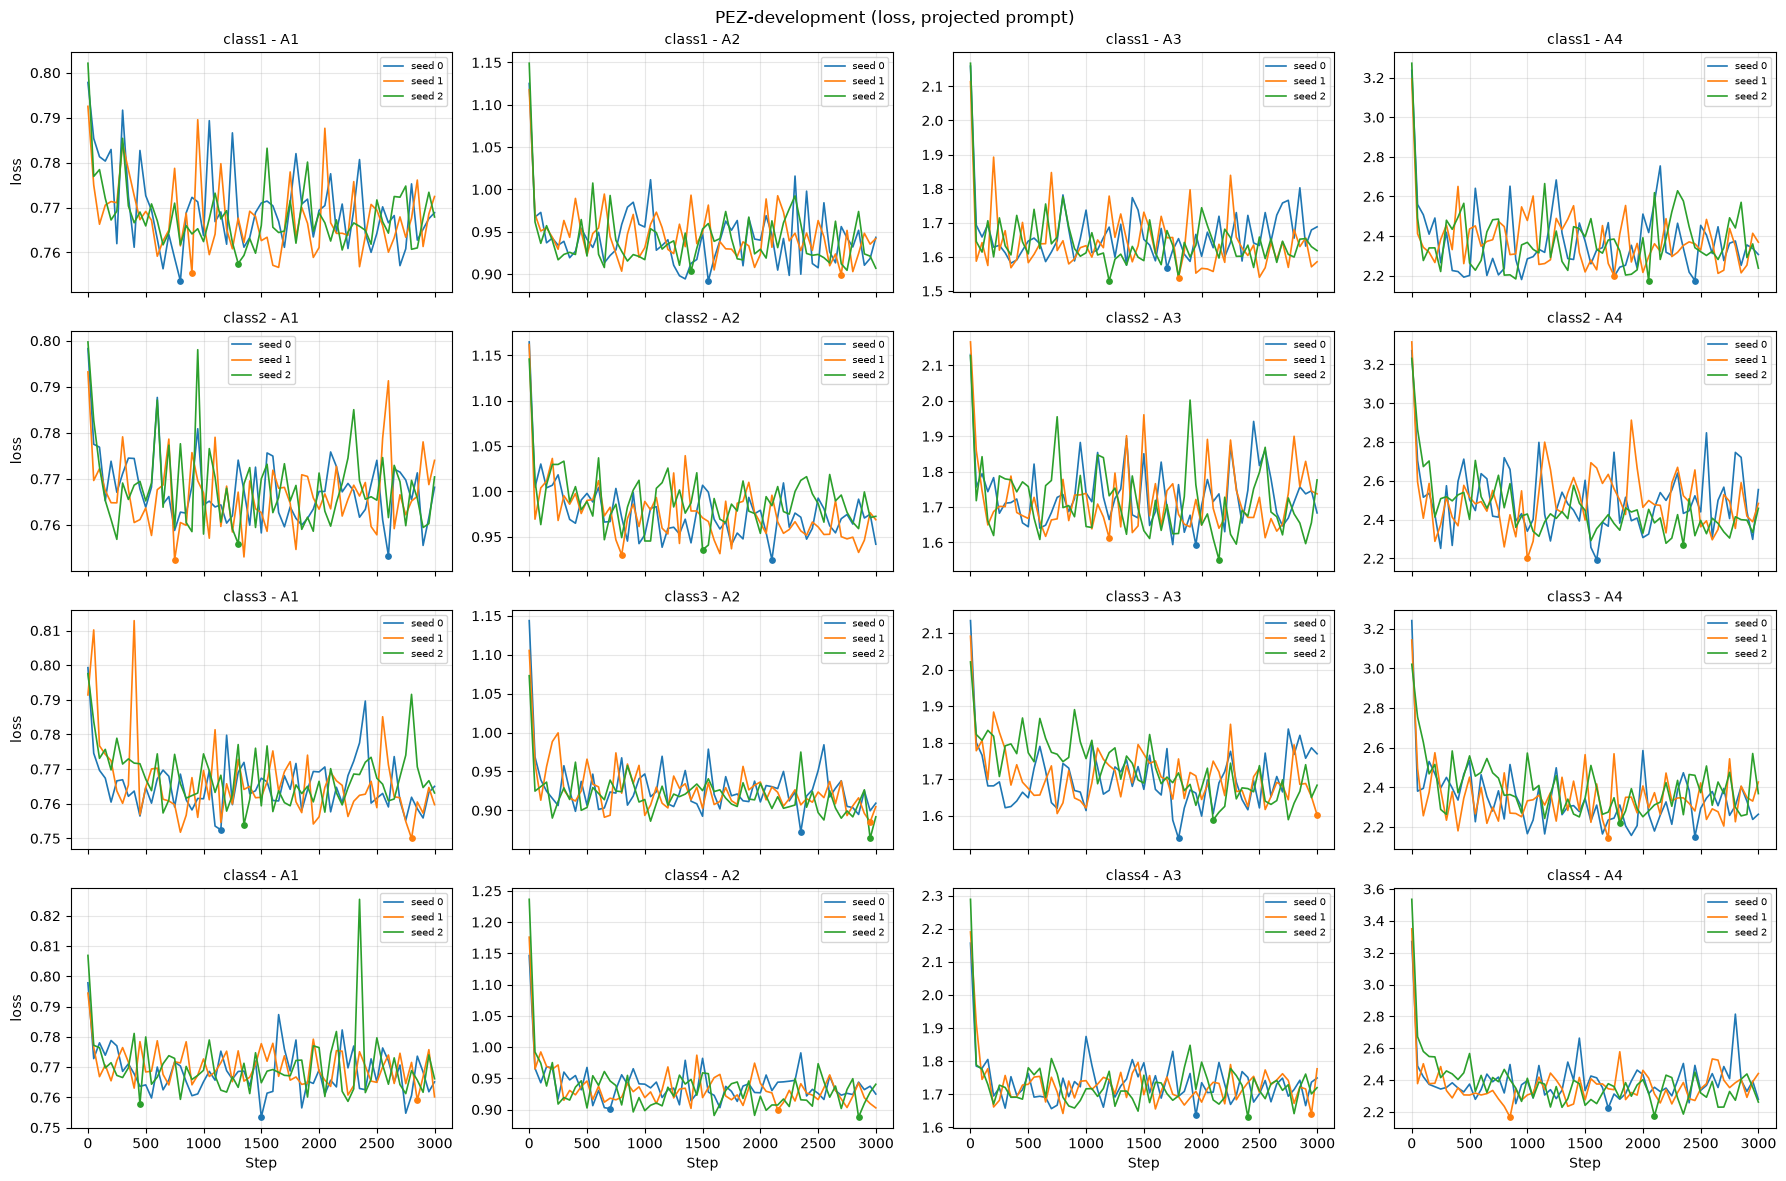

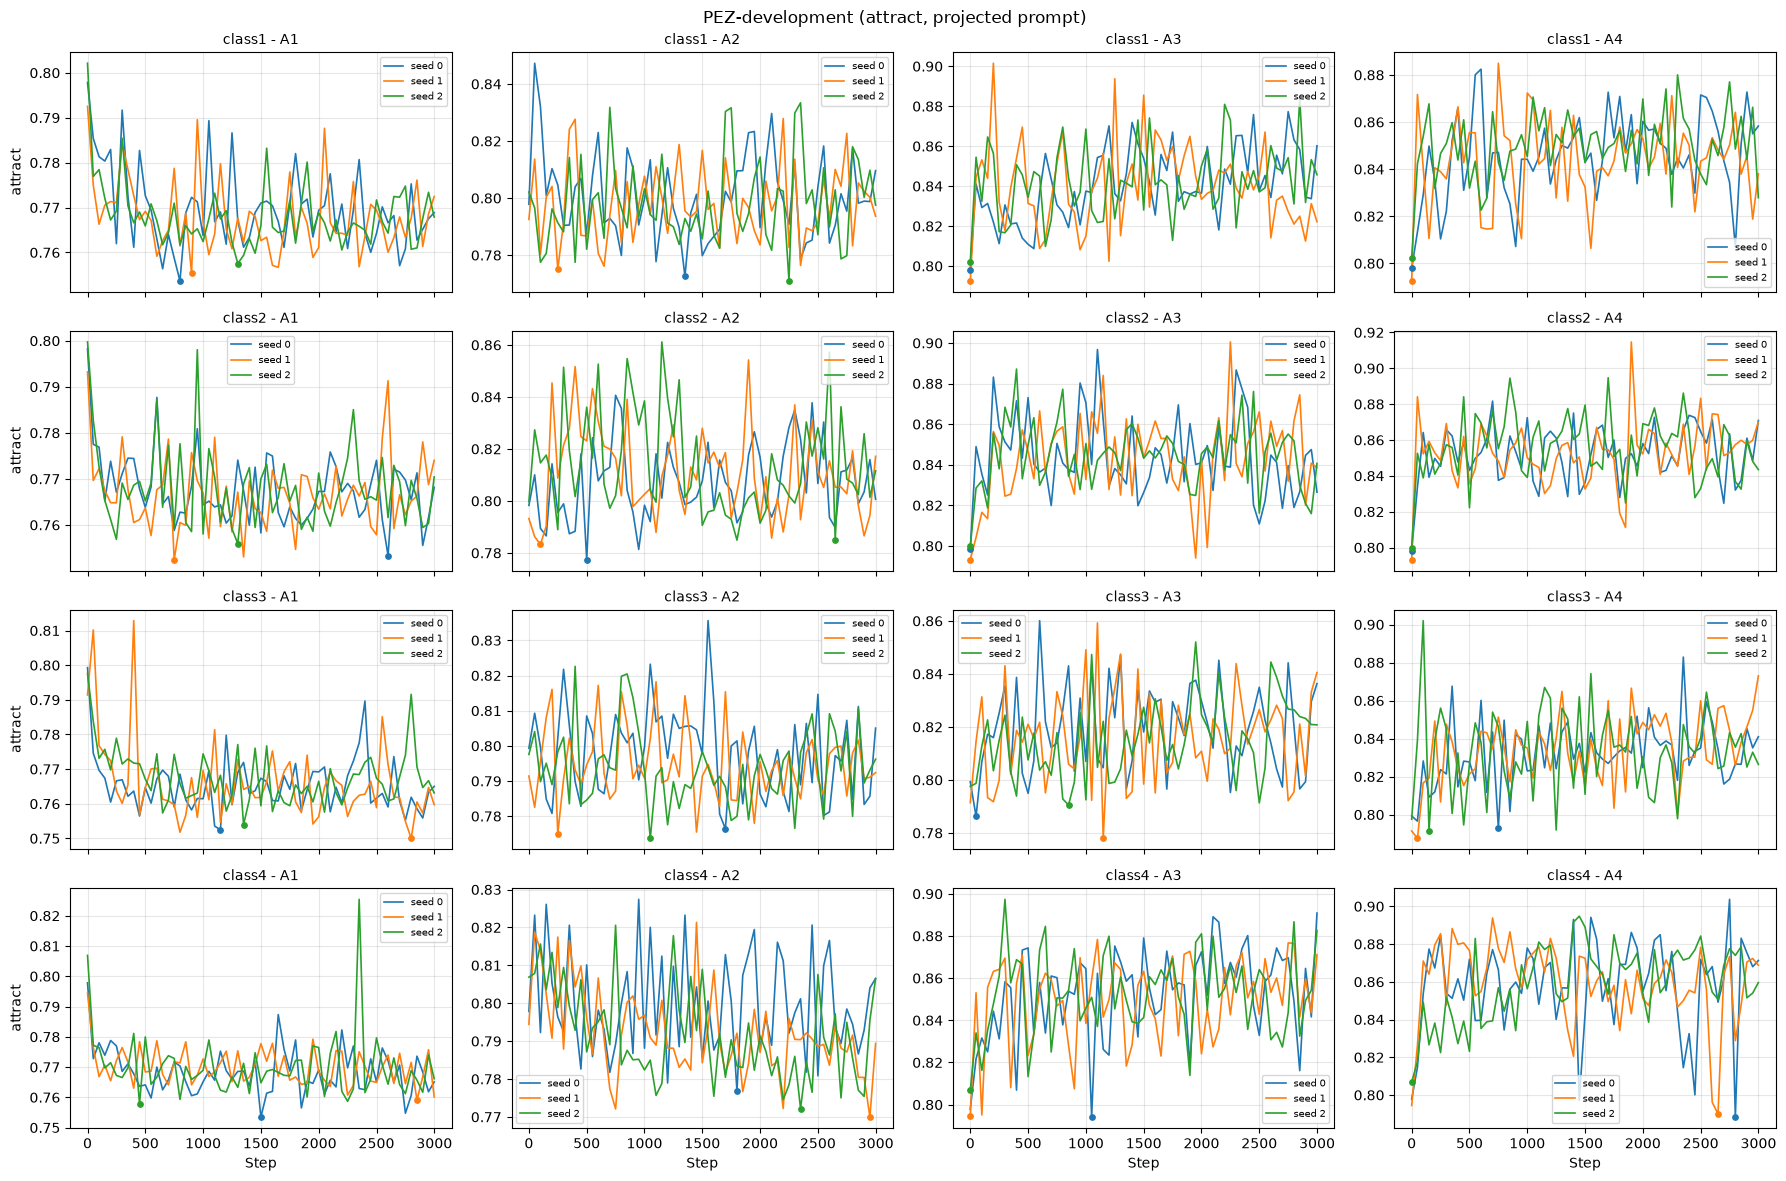

In [63]:
def plot_loss_curves(histories, key="loss", logy=False):
    variants = list(VARIANTS)
    fig, axes = plt.subplots(len(CLASSES), len(variants),
                             figsize=(4.5 * len(variants), 3 * len(CLASSES)),
                             sharex=True, squeeze=False)
    for r, cls in enumerate(CLASSES):
        for c, var in enumerate(variants):
            ax = axes[r, c]
            for (k_cls, k_var, seed), h in sorted(histories.items()):
                if k_cls == cls and k_var == var:
                    ax.plot(h["step"], h[key], label=f"seed {seed}", lw=1.2)
                    best = int(np.argmin(h[key]))
                    ax.scatter(h["step"][best], h[key][best], s=15, zorder=3)
            if logy:
                ax.set_yscale("log")
            ax.set_title(f"{cls} - {var}", fontsize=10)
            ax.grid(alpha=0.3)
            if r == len(CLASSES) - 1:
                ax.set_xlabel("Step")
            if c == 0:
                ax.set_ylabel(key)
            ax.legend(fontsize=7)
    fig.suptitle(f"PEZ-development ({key}, projected prompt)")
    plt.tight_layout()
    plt.show()

plot_loss_curves(histories, key="loss")
plot_loss_curves(histories, key="attract")

## Final Verification: Generate Prompts with stable diffusion and evaluate against API

In [65]:
pipe = StableDiffusionPipeline.from_pretrained(
    "sd-research/stable-diffusion-2-1-base",
    torch_dtype=torch.float16 if DEVICE.type == "cuda" else torch.float32,
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)

SEEDS = [1, 2]

def render(prompt, seeds=SEEDS):
    imgs = []
    for s in seeds:
        g = torch.Generator(device=DEVICE).manual_seed(s)
        imgs.append(pipe(prompt, guidance_scale=9, num_inference_steps=25, generator=g).images[0])
    return imgs

@torch.no_grad()
def surrogate_screen(imgs):
    feats, logits = embed_images(imgs)
    return feats, logits

Loading pipeline components...: 100%|██████████| 6/6 [00:46<00:00,  7.82s/it]


In [66]:
df_res = pd.DataFrame(results)

VARIANT = "A4"
sel = df_res[df_res.variant == VARIANT].sort_values(["class", "seed"])

renders = {}

def add_render(key, prompt):
    if key in renders:
        return
    imgs = render(prompt)
    feats, logits = surrogate_screen(imgs)
    renders[key] = {"prompt": prompt, "imgs": imgs, "feats": feats, "logits": logits}

for _, row in tqdm(sel.iterrows(), total=len(sel), desc="SD rendering"):
    add_render((row["class"], row.variant, row.seed), row.prompt)

SD rendering: 100%|██████████| 12/12 [12:05<00:00, 60.49s/it]


In [67]:
def query_api(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    r = requests.post(TARGET_SERVER_URL,
                      json={"image": base64.b64encode(buf.getvalue()).decode(), "classes": CLASSES},
                      timeout=60)
    r.raise_for_status()
    return r.json()

API: 100%|██████████| 12/12 [01:00<00:00,  5.02s/it]


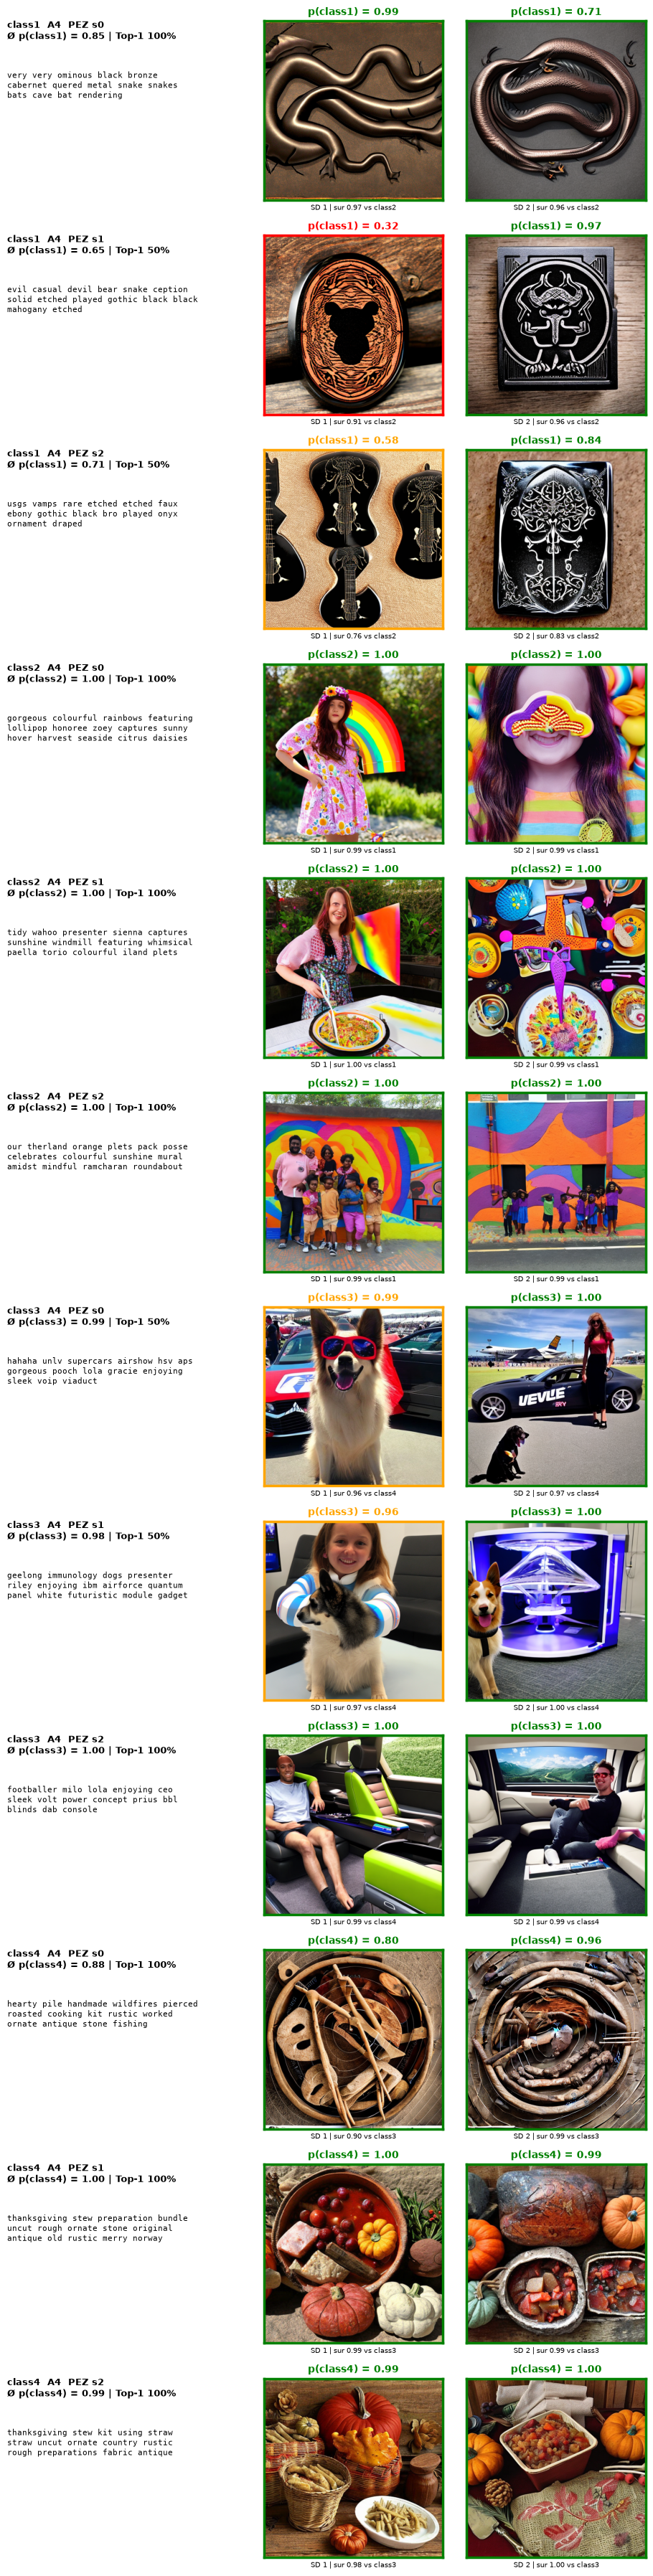

In [68]:
def api_probs(resp):
    p = resp.get("classes", resp)
    return {c: float(p[c]) for c in CLASSES}

for key, d in tqdm(renders.items(), desc="API"):
    if "api_p" not in d:
        d["api_p"] = [api_probs(query_api(img)) for img in d["imgs"]]
        d["api"] = [(np.log(p["class2"] / p["class1"]), np.log(p["class3"] / p["class4"]))
                    for p in d["api_p"]]

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def plot_renders(renders, keys=None, wrap=38):
    keys = keys or list(renders)
    n_rows, n_cols = len(keys), len(SEEDS)
    fig, axes = plt.subplots(
        n_rows, n_cols + 1,
        figsize=(3.6 + 2.8 * n_cols, 3.0 * n_rows),
        gridspec_kw={"width_ratios": [1.3] + [1] * n_cols},
        squeeze=False,
    )

    for r, key in enumerate(keys):
        cls, var, pez_seed = key
        d = renders[key]
        head, sign = CLASS_SPEC[cls]
        api_p = d.get("api_p", [])
        p_target = [p[cls] for p in api_p]

        tax = axes[r, 0]
        tax.axis("off")
        info = f"{cls}  {var}  PEZ s{pez_seed}"
        if p_target:
            top_rate = np.mean([max(p, key=p.get) == cls for p in api_p])
            info += f"\nØ p({cls}) = {np.mean(p_target):.2f} | Top-1 {top_rate:.0%}"
        tax.text(0, 1, info, fontsize=9, fontweight="bold", va="top", ha="left",
                 transform=tax.transAxes)
        tax.text(0, 0.72, textwrap.fill(d["prompt"], wrap), fontsize=8, va="top", ha="left",
                 family="monospace", transform=tax.transAxes)

        for c, (s, img) in enumerate(zip(SEEDS, d["imgs"])):
            ax = axes[r, c + 1]
            ax.imshow(img)
            ax.set_xticks([]); ax.set_yticks([])

            p_sur = sigmoid(sign * d["logits"][c, head])
            if api_p:
                p = api_p[c]
                is_top = max(p, key=p.get) == cls
                beats_sib = p[cls] > p[SIBLING[cls]]
                color = "green" if is_top else ("orange" if beats_sib else "red")
                ax.set_title(f"p({cls}) = {p[cls]:.2f}", fontsize=10, fontweight="bold", color=color)
                ax.set_xlabel(f"SD {s} | sur {p_sur:.2f} vs {SIBLING[cls]}", fontsize=7)
                for side in ax.spines.values():
                    side.set_edgecolor(color); side.set_linewidth(2.5)
            else:
                ax.set_title(f"SD {s} | sur {p_sur:.2f}", fontsize=9)

    plt.tight_layout()
    plt.show()

plot_renders(renders)

In [69]:
del pipe
torch.cuda.empty_cache() 